<div class="alert alert-info" style="color: black;">
    
### AI USE DISCLAIMER & ACADEMIC INTEGRITY COMPLIANCE
In compliance with the [**National University Student Guidelines for Generative AI**](https://resources.nu.edu/ai/ai-guidelines), this project discloses the following tool usage:

* **Conceptual Framing & Brainstorming (AI-Informed):** **Google Gemini** was utilized as a supplemental learning resource to clarify core mathematical and analytical concepts across the assignment questions. 
* **Technical Execution & Boilerplate Generation (AI-Assisted):** **Google Gemini** was used to generate initial code structures and programming boilerplates. These templates were subsequently modified, debugged, and tailored to meet the specific requirements of each question.
* **Human Oversight, Validation Loops & Refinement (Author-Owned):** The author maintained complete conceptual control, process oversight, and ownership of the entire homework scope. All AI-assisted templates, code logic, and conceptual outputs were systematically reviewed and validated by the author to ensure academic accuracy and integrity.
* **Disclosure Statement (AI-Generated):** **Google Gemini** was utilized to structure and audit this text format to fulfill all institutional reporting standards.
</div>

Genetic Algorithm Configuration and Mathematical Equations
Target Dimensions to Optimize: 2
Search Space Boundaries: -1.0 to 1.0
1. Loss Function Formula: Loss(x) = sum( |x_i|^(i+1) ) for i = 1 to n
2. Adjusted Loss Formula: Adjusted Loss = Loss(x) - min(Loss)
3. Model Fitness Transformation Formula: Fitness = 1.0 / (Adjusted Loss + 1e-6)
4. Selection Probability Distribution Formula: Weight = Fitness / sum(Fitness)
5. Linear Mutation Decay Formula: Step Size = Base Scale * (1.0 - (Current Generation / Total Generations))
6. Continuous Arithmetic Crossover Formula: Child = alpha * Parent1 + (1.0 - alpha) * Parent2 + Noise

Generation Step 1 of 150
Lowest Loss Score: 0.001002
Selection Weight Variance: 0.009871
Mutation Step Size: 0.0200
Fittest Model Advantage: 99.85x higher reproduction odds
Selection Odds Distribution Matrix for Generation 1
Rank     | Coordinate Vector      | Loss Score   | Selection Weight
Best     | [ 0.0316 -0.0156]      | 0.001002     | 99.85          %
2nd     

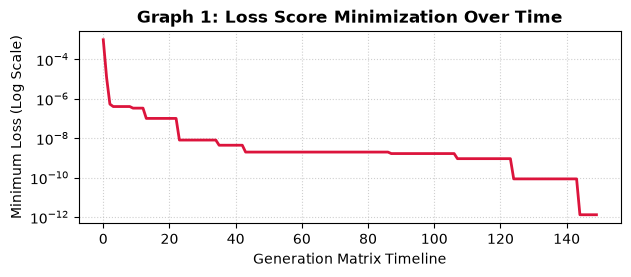

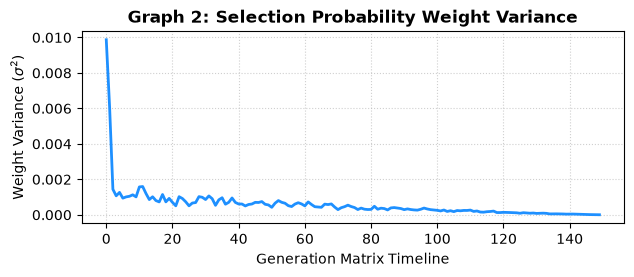

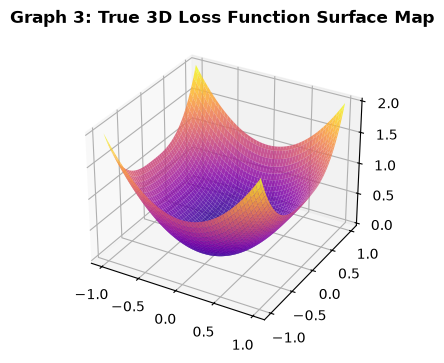

In [1]:
# ANA670 - Week 4 HW - Q1
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go

CONFIG = {
    "dimensions": 2,
    "pop_size": 100,         
    "generations": 150,      
    "mutation_scale": 0.02,  
    "bounds": (-1.0, 1.0)    
}

low, high = CONFIG["bounds"]
n = CONFIG["dimensions"]

print("Genetic Algorithm Configuration and Mathematical Equations")
print(f"Target Dimensions to Optimize: {n}")
print(f"Search Space Boundaries: {low} to {high}")
print("1. Loss Function Formula: Loss(x) = sum( |x_i|^(i+1) ) for i = 1 to n")
print("2. Adjusted Loss Formula: Adjusted Loss = Loss(x) - min(Loss)")
print("3. Model Fitness Transformation Formula: Fitness = 1.0 / (Adjusted Loss + 1e-6)")
print("4. Selection Probability Distribution Formula: Weight = Fitness / sum(Fitness)")
print("5. Linear Mutation Decay Formula: Step Size = Base Scale * (1.0 - (Current Generation / Total Generations))")
print("6. Continuous Arithmetic Crossover Formula: Child = alpha * Parent1 + (1.0 - alpha) * Parent2 + Noise")

def calculate_loss(x):
    return sum(np.abs(val)**(pos+2) for pos, val in enumerate(x))

def calculate_probabilities(loss_scores):
    best_loss = np.min(loss_scores)
    adjusted_loss = loss_scores - best_loss + 1e-6
    fitness_scores = 1.0 / adjusted_loss
    selection_weights = fitness_scores / np.sum(fitness_scores)
    weight_variance = np.var(selection_weights)
    max_advantage = np.max(selection_weights) / np.mean(selection_weights)
    return selection_weights, weight_variance, max_advantage

def show_data_table(population, loss_scores, selection_weights, gen):
    print(f"Selection Odds Distribution Matrix for Generation {gen}")
    print(f"{'Rank':<8} | {'Coordinate Vector':<22} | {'Loss Score':<12} | {'Selection Weight':<16}")
    order = np.argsort(loss_scores)
    ranks, idxs = ["Best", "2nd", "3rd", "Worst"], [order[0], order[1], order[2], order[-1]]
    for r, idx in zip(ranks, idxs):
        print(f"{r:<8} | {str(np.round(population[idx], 4)):<22} | {loss_scores[idx]:<12.6f} | {selection_weights[idx]*100:<15.2f}%")

def run_optimization(cfg):
    low_b, high_b = cfg["bounds"]
    population = np.random.uniform(low_b, high_b, (cfg["pop_size"], cfg["dimensions"]))
    loss_history, weight_variance_history = [], []
    snapshots, parent_snapshots = {}, {}
    milestones = [0, 14, 49, cfg["generations"] - 1]
    
    for g in range(cfg["generations"]):
        mutation_step = cfg["mutation_scale"] * (1.0 - (g / cfg["generations"]))
        loss_scores = np.array([calculate_loss(sample) for sample in population])
        selection_weights, var, advantage = calculate_probabilities(loss_scores)
        
        best_idx = np.argmin(loss_scores)
        best_loss = loss_scores[best_idx]
        loss_history.append(best_loss)
        weight_variance_history.append(var)
        
        if g in milestones:
            snapshots[g] = population.copy()
            
        if g == 0 or (g + 1) % 15 == 0 or g == cfg["generations"] - 1:
            print(f"\nGeneration Step {g+1} of {cfg['generations']}")
            print(f"Lowest Loss Score: {best_loss:.6f}")
            print(f"Selection Weight Variance: {var:.6f}")
            print(f"Mutation Step Size: {mutation_step:.4f}")
            print(f"Fittest Model Advantage: {advantage:.2f}x higher reproduction odds")
            show_data_table(population, loss_scores, selection_weights, g+1)
            
        next_gen = [population[best_idx].copy()]
        parents = []
        
        while len(next_gen) < cfg["pop_size"]:
            i1, i2 = np.random.choice(cfg["pop_size"], size=2, p=selection_weights, replace=False)
            p1, p2 = population[i1], population[i2]
            parents.extend([p1.copy(), p2.copy()])
            
            blend = np.random.rand()
            c1 = blend * p1 + (1 - blend) * p2 + np.random.normal(0, mutation_step, cfg["dimensions"])
            c2 = blend * p2 + (1 - blend) * p1 + np.random.normal(0, mutation_step, cfg["dimensions"])
            next_gen.extend([np.clip(c1, low_b, high_b), np.clip(c2, low_b, high_b)])
            
        if g in milestones:
            parent_snapshots[g] = np.array(parents)
        population = np.array(next_gen[:cfg["pop_size"]])
        
    return loss_history, weight_variance_history, snapshots, parent_snapshots
loss_hist, var_hist, frames, parent_frames = run_optimization(CONFIG)

print("\nGenerating Statistical Visualizations")
plt.figure(figsize=(7, 2.5))
plt.plot(loss_hist, color='crimson', linewidth=2)
plt.title('Graph 1: Loss Score Minimization Over Time', fontweight='bold')
plt.xlabel('Generation Matrix Timeline')
plt.ylabel('Minimum Loss (Log Scale)')
plt.yscale('log')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

plt.figure(figsize=(7, 2.5))
plt.plot(var_hist, color='dodgerblue', linewidth=2)
plt.title('Graph 2: Selection Probability Weight Variance', fontweight='bold')
plt.xlabel('Generation Matrix Timeline')
plt.ylabel(r'Weight Variance ($\sigma^2$)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

if CONFIG["dimensions"] == 1:
    x_space = np.linspace(low, high, 500)
    y_space = np.abs(x_space)**2
    
    plt.figure(figsize=(7, 2.5))
    plt.plot(x_space, y_space, color='purple', linewidth=2)
    plt.title('Graph 3: True 2D Loss Function Surface Curve', fontweight='bold')
    plt.xlabel('Feature Vector Position')
    plt.ylabel('Loss Value')
    plt.grid(True, alpha=0.4)
    plt.show()
    
    plt.figure(figsize=(7, 3.5))
    plt.plot(x_space, y_space, color='black', alpha=0.15, linestyle='--')
    milestones, names, colors = [0, 14, 49, CONFIG["generations"] - 1], ["Gen 1", "Gen 15", "Gen 50", "Gen 150"], ['gray', 'coral', 'mediumpurple', 'mediumblue']
    for i, gen_idx in enumerate(milestones):
        current_pop = frames[gen_idx][:, 0]
        plt.scatter(current_pop, np.abs(current_pop)**2, color=colors[i], alpha=0.6, label=names[i], s=25)
    plt.title('Graph 4: Sample Population Convergence Along Loss Surface', fontweight='bold')
    plt.xlabel('Feature Vector Position')
    plt.ylabel('Loss Value')
    plt.grid(True, alpha=0.25)
    plt.legend()
    plt.show()

elif CONFIG["dimensions"] == 2:
    x_space = np.linspace(low, high, 100)
    y_space = np.linspace(low, high, 100)
    X, Y = np.meshgrid(x_space, y_space)
    Z = np.abs(X)**2 + np.abs(Y)**3

    fig = plt.figure(figsize=(6, 4))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(X, Y, Z, cmap='plasma', edgecolor='none', alpha=0.85)
    ax.set_title('Graph 3: True 3D Loss Function Surface Map', fontweight='bold')
    plt.show()

    fig_3d = go.Figure()
    x_surf, y_surf = np.linspace(low, high, 60), np.linspace(low, high, 60)
    X_surf, Y_surf = np.meshgrid(x_surf, y_surf)
    fig_3d.add_trace(go.Surface(x=x_surf, y=y_surf, z=np.abs(X_surf)**2 + np.abs(Y_surf)**3, colorscale='plasma', opacity=0.30, showscale=False))

    milestones, names, colors = [0, 14, 49, CONFIG["generations"] - 1], ["Gen 1 Space", "Gen 15 Space", "Gen 50 Space", "Gen 150 Space"], ['#888888', '#FF6F59', '#9370DB', '#0000CD']
    for i, gen_idx in enumerate(milestones):
        curr_pop, curr_parents = frames[gen_idx], parent_frames[gen_idx]
        p_scores = np.array([calculate_loss(sample) for sample in curr_pop])
        parent_scores = np.array([calculate_loss(sample) for sample in curr_parents])
        fig_3d.add_trace(go.Scatter3d(x=curr_pop[:, 0], y=curr_pop[:, 1], z=p_scores, mode='markers', marker=dict(size=4.5, color=colors[i], opacity=0.9), name=names[i]))
        fig_3d.add_trace(go.Scatter3d(x=curr_parents[:, 0], y=curr_parents[:, 1], z=parent_scores, mode='markers', marker=dict(size=6.5, color='rgba(0,0,0,0)', line=dict(color='#00FF00', width=3.5)), name=f"Mating Samples at Gen {gen_idx+1}", visible="legendonly" if i > 1 else True))
    fig_3d.update_layout(title=dict(text='Interactive 3D Optimization and Sinking Environment Cloud', font=dict(size=14, weight="bold")), scene=dict(xaxis=dict(title='X Coordinate Axis', range=[low, high]), yaxis=dict(title='Y Coordinate Axis', range=[low, high]), zaxis=dict(title='Calculated Loss Height', range=[0, 2.0]), aspectmode='cube'), margin=dict(l=0, r=0, b=0, t=40), width=850, height=650, legend=dict(yanchor="top", y=0.99, xanchor="left", x=0.01))
    fig_3d.show()
else:
    print(f"\nSpatial models cannot render a complex {CONFIG['dimensions']}-dimensional feature vector space on a lower-dimensional grid coordinate layout.")

=== OPTIMIZATION RUN METADATA ===
Target Dimension Count: 2
Search Space Bounds: [-6.2832, 6.2832]
Initial Temperature Setting: 100.0
Cooling Rate Coefficient: 0.95
Total Iterations Allocated: 1000
Neighbor Search Step Size: 1.3

=== MATHEMATICAL EQUATIONS IN PROCESS ===
Objective Function / Error Metric:
  Loss = (Sum of Absolute Values) * Exp( -1 * Sum of Sine of Squared Values )
Acceptance Probability Formula (for worse moves):
  Probability = Exp( -1 * (New Loss - Current Loss) / Current Temperature )
Cooling Schedule Model:
  New Temperature = Current Temperature * Cooling Rate

Step 1/1000 | Temperature: 95.0000 | Loss: 4.913602 | Best Loss: 2.125676
Step 100/1000 | Temperature: 0.5921 | Loss: 0.834198 | Best Loss: 0.770095
Step 200/1000 | Temperature: 0.0035 | Loss: 0.350362 | Best Loss: 0.350362
Step 300/1000 | Temperature: 0.0000 | Loss: 0.089841 | Best Loss: 0.089841
Step 400/1000 | Temperature: 0.0000 | Loss: 0.089841 | Best Loss: 0.089841
Step 500/1000 | Temperature: 0.0000

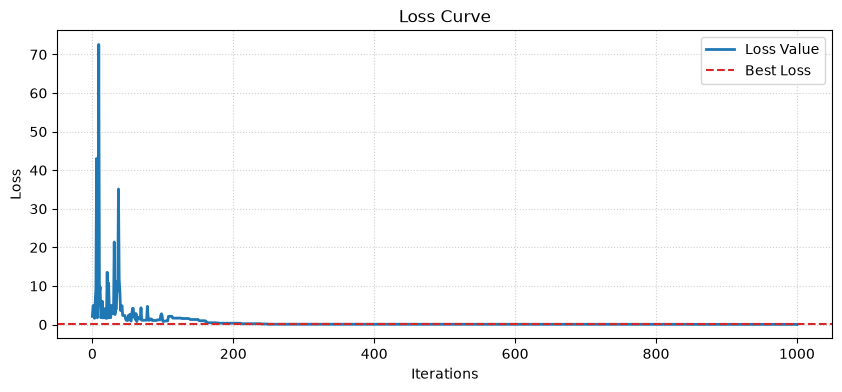

In [2]:
# ANA670 - Week 4 HW - Q2
number_of_dimensions = 2
minimum_boundary = -2 * np.pi
maximum_boundary = 2 * np.pi
initial_temperature = 100.0 
cooling_rate = 0.95  
total_iterations = 1000
step_size_radius = 1.3

print("=== OPTIMIZATION RUN METADATA ===")
print(f"Target Dimension Count: {number_of_dimensions}")
print(f"Search Space Bounds: [{minimum_boundary:.4f}, {maximum_boundary:.4f}]")
print(f"Initial Temperature Setting: {initial_temperature}")
print(f"Cooling Rate Coefficient: {cooling_rate}")
print(f"Total Iterations Allocated: {total_iterations}")
print(f"Neighbor Search Step Size: {step_size_radius}")
print("=================================\n")
print("=== MATHEMATICAL EQUATIONS IN PROCESS ===")
print("Objective Function / Error Metric:")
print("  Loss = (Sum of Absolute Values) * Exp( -1 * Sum of Sine of Squared Values )")
print("Acceptance Probability Formula (for worse moves):")
print("  Probability = Exp( -1 * (New Loss - Current Loss) / Current Temperature )")
print("Cooling Schedule Model:")
print("  New Temperature = Current Temperature * Cooling Rate")
print("=========================================\n")

def calculate_loss_score(input_features):
    absolute_sum = np.sum(np.abs(input_features))
    sine_squared_sum = np.sum(np.sin(input_features**2))
    return absolute_sum * np.exp(-sine_squared_sum)
    
np.random.seed(42)
current_features = np.random.uniform(minimum_boundary, maximum_boundary, number_of_dimensions)
current_loss = calculate_loss_score(current_features)
best_features = np.copy(current_features)
best_loss = current_loss
worst_features = np.copy(current_features)
worst_loss = current_loss
all_features_evaluated = [np.copy(current_features)]
all_losses_evaluated = [current_loss]
current_temperature = initial_temperature
loss_history = [current_loss]
feature_trajectory_history = [np.copy(current_features)]

for step in range(1, total_iterations + 1):
    random_mutation = np.random.uniform(-step_size_radius, step_size_radius, number_of_dimensions)
    candidate_features = np.clip(current_features + random_mutation, minimum_boundary, maximum_boundary)
    candidate_loss = calculate_loss_score(candidate_features)
    all_features_evaluated.append(np.copy(candidate_features))
    all_losses_evaluated.append(candidate_loss)
    
    loss_difference = candidate_loss - current_loss
    if loss_difference < 0:
        current_features = np.copy(candidate_features)
        current_loss = candidate_loss
    else:
        if np.random.rand() < np.exp(-loss_difference / current_temperature):
            current_features = np.copy(candidate_features)
            current_loss = candidate_loss
    if current_loss < best_loss:
        best_features = np.copy(current_features)
        best_loss = current_loss
    if candidate_loss > worst_loss:
        worst_features = np.copy(candidate_features)
        worst_loss = candidate_loss
    current_temperature *= cooling_rate
    loss_history.append(current_loss)
    feature_trajectory_history.append(np.copy(current_features))
    if step % (total_iterations // 10) == 0 or step == 1:
        print(f"Step {step}/{total_iterations} | Temperature: {current_temperature:.4f} | Loss: {current_loss:.6f} | Best Loss: {best_loss:.6f}")

sorted_indices = np.argsort(all_losses_evaluated)
median_index = sorted_indices[len(sorted_indices) // 2]
middle_features = all_features_evaluated[median_index]
middle_loss = all_losses_evaluated[median_index]

print("\n=== SEARCH COMPLETED ===")
print(f"Best Coordinates: {best_features} | Score: {best_loss:.6f}")
print(f"Middle Coordinates: {middle_features} | Score: {middle_loss:.6f}")
print(f"Worst Coordinates: {worst_features} | Score: {worst_loss:.6f}\n")

feature_trajectory_history = np.array(feature_trajectory_history)
loss_history = np.array(loss_history)

plt.figure(figsize=(10, 4))
plt.plot(loss_history, color='tab:blue', linewidth=2, label='Loss Value')
plt.axhline(y=best_loss, color='tab:red', linestyle='--', label='Best Loss')
plt.title('Loss Curve', fontsize=12)
plt.xlabel('Iterations', fontsize=10)
plt.ylabel('Loss', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

if number_of_dimensions == 1:
    plt.figure(figsize=(10, 5))
    grid_axis_x = np.linspace(minimum_boundary, maximum_boundary, 500)
    mesh_loss_landscape = np.abs(grid_axis_x) * np.exp(-np.sin(grid_axis_x**2))
    plt.plot(grid_axis_x, mesh_loss_landscape, color='gray', alpha=0.5, label='Landscape')
    trajectory_losses = np.array([calculate_loss_score(pt) for pt in feature_trajectory_history])
    plt.plot(feature_trajectory_history[:, 0], trajectory_losses, color='blue', alpha=0.4, label='Path')
    halfway_index = int(total_iterations * 0.75)
    plt.scatter(feature_trajectory_history[halfway_index:, 0], trajectory_losses[halfway_index:], c=np.arange(halfway_index, total_iterations + 1), cmap='autumn', s=15, label='Final Steps', zorder=3)
    plt.scatter(feature_trajectory_history[:, 0], trajectory_losses, color='blue', s=100, label='Start', zorder=4)
    plt.scatter(best_features, best_loss, color='cyan', marker='*', s=200, edgecolor='black', label='Best', zorder=5)
    plt.title('Optimization Landscape', fontsize=12)
    plt.xlabel('X')
    plt.ylabel('Loss')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
    plt.show()
elif number_of_dimensions == 2:
    grid_axis_x = np.linspace(minimum_boundary, maximum_boundary, 100)
    grid_axis_y = np.linspace(minimum_boundary, maximum_boundary, 100)
    mesh_x, mesh_y = np.meshgrid(grid_axis_x, grid_axis_y)
    mesh_loss_landscape = (np.abs(mesh_x) + np.abs(mesh_y)) * np.exp(-(np.sin(mesh_x**2) + np.sin(mesh_y**2)))
    trajectory_losses = np.array([calculate_loss_score(pt) for pt in feature_trajectory_history])
    halfway_index = int(total_iterations * 0.75)
    fig = go.Figure()
    fig.add_trace(go.Surface(x=grid_axis_x, y=grid_axis_y, z=mesh_loss_landscape, colorscale='Viridis', opacity=0.6, showscale=True, colorbar=dict(title='Loss', x=1.15)))
    fig.add_trace(go.Scatter3d(x=feature_trajectory_history[:, 0], y=feature_trajectory_history[:, 1], z=trajectory_losses, mode='lines', line=dict(color='white', width=4), name='Path'))
    fig.add_trace(go.Scatter3d(x=feature_trajectory_history[halfway_index:, 0], y=feature_trajectory_history[halfway_index:, 1], z=trajectory_losses[halfway_index:], mode='markers', marker=dict(size=3, color=np.arange(halfway_index, total_iterations + 1), colorscale='Hot', showscale=False), name='Final Steps'))
    fig.add_trace(go.Scatter3d(x=[feature_trajectory_history[0, 0]], y=[feature_trajectory_history[0, 1]], z=[trajectory_losses[0]], mode='markers', marker=dict(size=10, color='blue', symbol='circle'), name='Start'))
    fig.add_trace(go.Scatter3d(x=[best_features[0]], y=[best_features[1]], z=[best_loss], mode='markers', marker=dict(size=12, color='cyan', symbol='diamond'), name='Best'))
    fig.update_layout(title='Optimization Landscape', scene=dict(xaxis_title='x1', yaxis_title='x2', zaxis_title='f(x)'), legend=dict(x=0.05, y=0.95, bgcolor='rgba(255,255,255,0.6)'), margin=dict(l=0, r=100, b=0, t=40))
    fig.show()
else:
    print(f"Skipping spatial map plots: Total coordinates layout ({number_of_dimensions + 1} dimensions) exceeds 3 printable visualization planes.")

=== OPTIMIZATION RUN METADATA ===
Target Dimension Count: 2
Search Space Bounds: [-6.2832, 6.2832]
Initial Temperature Setting: 100.0
Alpha Decay Rate: 0.035
Total Iterations Allocated: 1000
Neighbor Search Step Size: 1.3

=== MATHEMATICAL EQUATIONS IN PROCESS ===
Objective Function / Error Metric:
  Loss = (Sum of Absolute Values) * Exp( -1 * Sum of Sine of Squared Values )
Acceptance Probability Formula (for worse moves):
  Probability = Exp( -1 * (New Loss - Current Loss) / Current Temperature )
Non-Monotonic Cosine Squared Cooling Schedule Model:
  Temperature(Step) = Initial Temperature * (Cos(Step)**2) * Exp( -Alpha * Step )

Step 1/1000 | Temperature: 28.1886 | Loss: 4.913602 | Best Loss: 2.125676
Step 100/1000 | Temperature: 2.2455 | Loss: 1.007086 | Best Loss: 0.356163
Step 200/1000 | Temperature: 0.0216 | Loss: 0.340180 | Best Loss: 0.000323
Step 300/1000 | Temperature: 0.0000 | Loss: 0.299795 | Best Loss: 0.000323
Step 400/1000 | Temperature: 0.0000 | Loss: 0.142272 | Best L

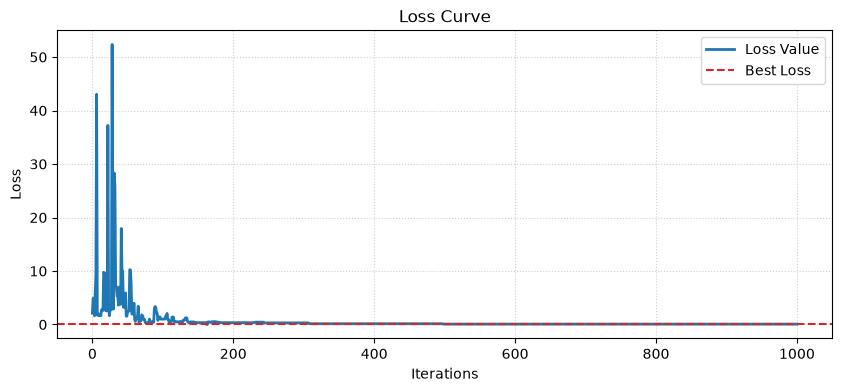

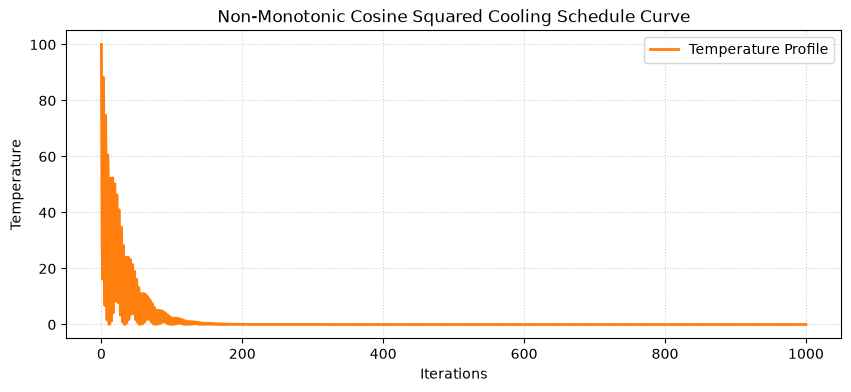

In [3]:
# ANA670 - Week 4 HW - Q3
number_of_dimensions = 2
minimum_boundary = -2 * np.pi
maximum_boundary = 2 * np.pi
initial_temperature = 100.00
alpha_coefficient = 0.035  
total_iterations = 1000
step_size_radius = 1.3

print("=== OPTIMIZATION RUN METADATA ===")
print(f"Target Dimension Count: {number_of_dimensions}")
print(f"Search Space Bounds: [{minimum_boundary:.4f}, {maximum_boundary:.4f}]")
print(f"Initial Temperature Setting: {initial_temperature}")
print(f"Alpha Decay Rate: {alpha_coefficient}")
print(f"Total Iterations Allocated: {total_iterations}")
print(f"Neighbor Search Step Size: {step_size_radius}")
print("=================================\n")
print("=== MATHEMATICAL EQUATIONS IN PROCESS ===")
print("Objective Function / Error Metric:")
print("  Loss = (Sum of Absolute Values) * Exp( -1 * Sum of Sine of Squared Values )")
print("Acceptance Probability Formula (for worse moves):")
print("  Probability = Exp( -1 * (New Loss - Current Loss) / Current Temperature )")
print("Non-Monotonic Cosine Squared Cooling Schedule Model:")
print("  Temperature(Step) = Initial Temperature * (Cos(Step)**2) * Exp( -Alpha * Step )")
print("=========================================\n")

def calculate_loss_score(input_features):
    absolute_sum = np.sum(np.abs(input_features))
    sine_squared_sum = np.sum(np.sin(input_features**2))
    return absolute_sum * np.exp(-sine_squared_sum)
    
np.random.seed(42)
current_features = np.random.uniform(minimum_boundary, maximum_boundary, number_of_dimensions)
current_loss = calculate_loss_score(current_features)
best_features = np.copy(current_features)
best_loss = current_loss
worst_features = np.copy(current_features)
worst_loss = current_loss
all_features_evaluated = [np.copy(current_features)]
all_losses_evaluated = [current_loss]
current_temperature = initial_temperature
loss_history = [current_loss]
temperature_history = [current_temperature]
feature_trajectory_history = [np.copy(current_features)]

for step in range(1, total_iterations + 1):
    current_temperature = initial_temperature * (np.cos(step) ** 2) * np.exp(-alpha_coefficient * step)
    current_temperature = max(current_temperature, 1e-10)
    random_mutation = np.random.uniform(-step_size_radius, step_size_radius, number_of_dimensions)
    candidate_features = np.clip(current_features + random_mutation, minimum_boundary, maximum_boundary)
    candidate_loss = calculate_loss_score(candidate_features)
    all_features_evaluated.append(np.copy(candidate_features))
    all_losses_evaluated.append(candidate_loss)
    loss_difference = candidate_loss - current_loss
    if loss_difference < 0:
        current_features = np.copy(candidate_features)
        current_loss = candidate_loss
    else:
        if np.random.rand() < np.exp(-loss_difference / current_temperature):
            current_features = np.copy(candidate_features)
            current_loss = candidate_loss
    if current_loss < best_loss:
        best_features = np.copy(current_features)
        best_loss = current_loss
    if candidate_loss > worst_loss:
        worst_features = np.copy(candidate_features)
        worst_loss = candidate_loss
    loss_history.append(current_loss)
    temperature_history.append(current_temperature)
    feature_trajectory_history.append(np.copy(current_features))
    if step % (total_iterations // 10) == 0 or step == 1:
        print(f"Step {step}/{total_iterations} | Temperature: {current_temperature:.4f} | Loss: {current_loss:.6f} | Best Loss: {best_loss:.6f}")

sorted_indices = np.argsort(all_losses_evaluated)
median_index = sorted_indices[len(sorted_indices) // 2]
middle_features = all_features_evaluated[median_index]
middle_loss = all_losses_evaluated[median_index]

print("\n=== SEARCH COMPLETED ===")
print(f"Best Coordinates: {best_features} | Score: {best_loss:.6f}")
print(f"Middle Coordinates: {middle_features} | Score: {middle_loss:.6f}")
print(f"Worst Coordinates: {worst_features} | Score: {worst_loss:.6f}\n")

feature_trajectory_history = np.array(feature_trajectory_history)
loss_history = np.array(loss_history)

plt.figure(figsize=(10, 4))
plt.plot(loss_history, color='tab:blue', linewidth=2, label='Loss Value')
plt.axhline(y=best_loss, color='tab:red', linestyle='--', label='Best Loss')
plt.title('Loss Curve', fontsize=12)
plt.xlabel('Iterations', fontsize=10)
plt.ylabel('Loss', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()
plt.figure(figsize=(10, 4))
plt.plot(temperature_history, color='tab:orange', linewidth=2, label='Temperature Profile')
plt.title('Non-Monotonic Cosine Squared Cooling Schedule Curve', fontsize=12)
plt.xlabel('Iterations', fontsize=10)
plt.ylabel('Temperature', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

if number_of_dimensions == 1:
    plt.figure(figsize=(10, 5))
    grid_axis_x = np.linspace(minimum_boundary, maximum_boundary, 500)
    mesh_loss_landscape = np.abs(grid_axis_x) * np.exp(-np.sin(grid_axis_x**2))
    plt.plot(grid_axis_x, mesh_loss_landscape, color='gray', alpha=0.5, label='Landscape')
    trajectory_losses = np.array([calculate_loss_score(pt) for pt in feature_trajectory_history])
    plt.plot(feature_trajectory_history[:, 0], trajectory_losses, color='blue', alpha=0.4, label='Path')
    halfway_index = int(total_iterations * 0.75)
    plt.scatter(feature_trajectory_history[halfway_index:, 0], trajectory_losses[halfway_index:], c=np.arange(halfway_index, total_iterations + 1), cmap='autumn', s=15, label='Final Steps', zorder=3)
    plt.scatter(feature_trajectory_history[:, 0], trajectory_losses, color='blue', s=100, label='Start', zorder=4)
    plt.scatter(best_features, best_loss, color='cyan', marker='*', s=200, edgecolor='black', label='Best', zorder=5)
    plt.title('Optimization Landscape', fontsize=12)
    plt.xlabel('X')
    plt.ylabel('Loss')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
    plt.show()
elif number_of_dimensions == 2:
    grid_axis_x = np.linspace(minimum_boundary, maximum_boundary, 100)
    grid_axis_y = np.linspace(minimum_boundary, maximum_boundary, 100)
    mesh_x, mesh_y = np.meshgrid(grid_axis_x, grid_axis_y)
    mesh_loss_landscape = (np.abs(mesh_x) + np.abs(mesh_y)) * np.exp(-(np.sin(mesh_x**2) + np.sin(mesh_y**2)))
    trajectory_losses = np.array([calculate_loss_score(pt) for pt in feature_trajectory_history])
    halfway_index = int(total_iterations * 0.75)
    fig = go.Figure()
    fig.add_trace(go.Surface(x=grid_axis_x, y=grid_axis_y, z=mesh_loss_landscape, colorscale='Viridis', opacity=0.6, showscale=True, colorbar=dict(title='Loss', x=1.15)))
    fig.add_trace(go.Scatter3d(x=feature_trajectory_history[:, 0], y=feature_trajectory_history[:, 1], z=trajectory_losses, mode='lines', line=dict(color='white', width=4), name='Path'))
    fig.add_trace(go.Scatter3d(x=feature_trajectory_history[halfway_index:, 0], y=feature_trajectory_history[halfway_index:, 1], z=trajectory_losses[halfway_index:], mode='markers', marker=dict(size=3, color=np.arange(halfway_index, total_iterations + 1), colorscale='Hot', showscale=False), name='Final Steps'))
    fig.add_trace(go.Scatter3d(x=[feature_trajectory_history], y=[feature_trajectory_history], z=[trajectory_losses], mode='markers', marker=dict(size=10, color='blue', symbol='circle'), name='Start'))
    fig.add_trace(go.Scatter3d(x=[best_features], y=[best_features], z=[best_loss], mode='markers', marker=dict(size=12, color='cyan', symbol='diamond'), name='Best'))
    fig.update_layout(title='Optimization Landscape', scene=dict(xaxis_title='x1', yaxis_title='x2', zaxis_title='f(x)'), legend=dict(x=0.05, y=0.95, bgcolor='rgba(255,255,255,0.6)'), margin=dict(l=0, r=100, b=0, t=40))
    fig.show()
else:
    print(f"Skipping spatial map plots: Total coordinates layout ({number_of_dimensions + 1} dimensions) exceeds 3 printable visualization planes.")

=== START ===
Loaded nodes and distance matrix.

Running alpha = 0.005 (multiplier = 0.9950)
  Cycle  0: Best distance = 518.12 miles
    └─ Scent Check: Evaporated Avg = -0.0014 | Total Deposited = +13.0930 | Matrix New Avg = 0.9986
  Cycle 30: Best distance = 464.13 miles
    └─ Scent Check: Evaporated Avg = -0.0003 | Total Deposited = +16.1870 | Matrix New Avg = 0.9709
  Cycle 59: Best distance = 305.14 miles
    └─ Scent Check: Evaporated Avg = --0.0012 | Total Deposited = +21.9762 | Matrix New Avg = 0.9805

Running alpha = 0.01 (multiplier = 0.9900)
  Cycle  0: Best distance = 583.66 miles
    └─ Scent Check: Evaporated Avg = -0.0062 | Total Deposited = +13.3523 | Matrix New Avg = 0.9938
  Cycle 30: Best distance = 422.31 miles
    └─ Scent Check: Evaporated Avg = -0.0038 | Total Deposited = +16.5603 | Matrix New Avg = 0.8413
  Cycle 59: Best distance = 313.84 miles
    └─ Scent Check: Evaporated Avg = -0.0012 | Total Deposited = +23.0975 | Matrix New Avg = 0.7676

Running alpha =

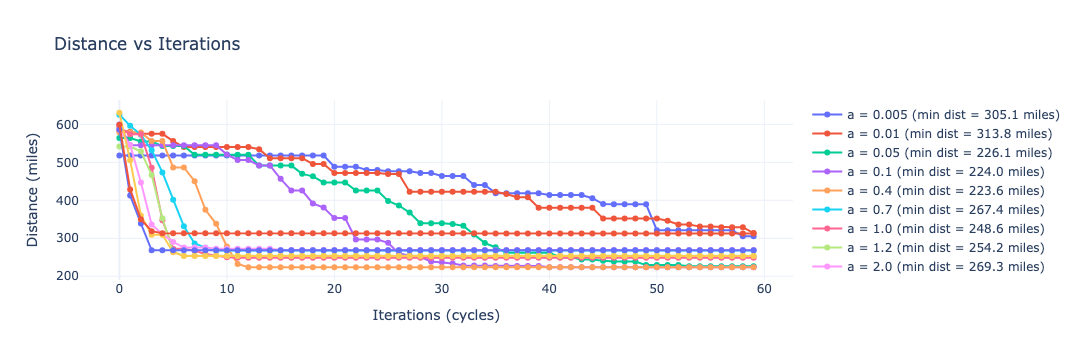

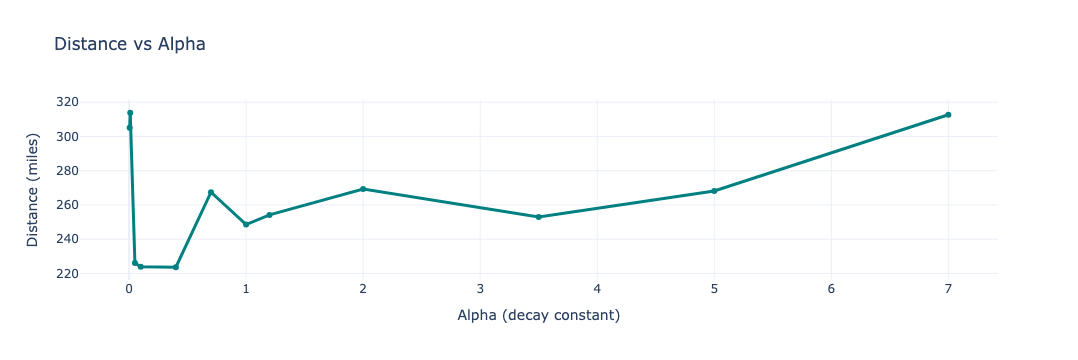

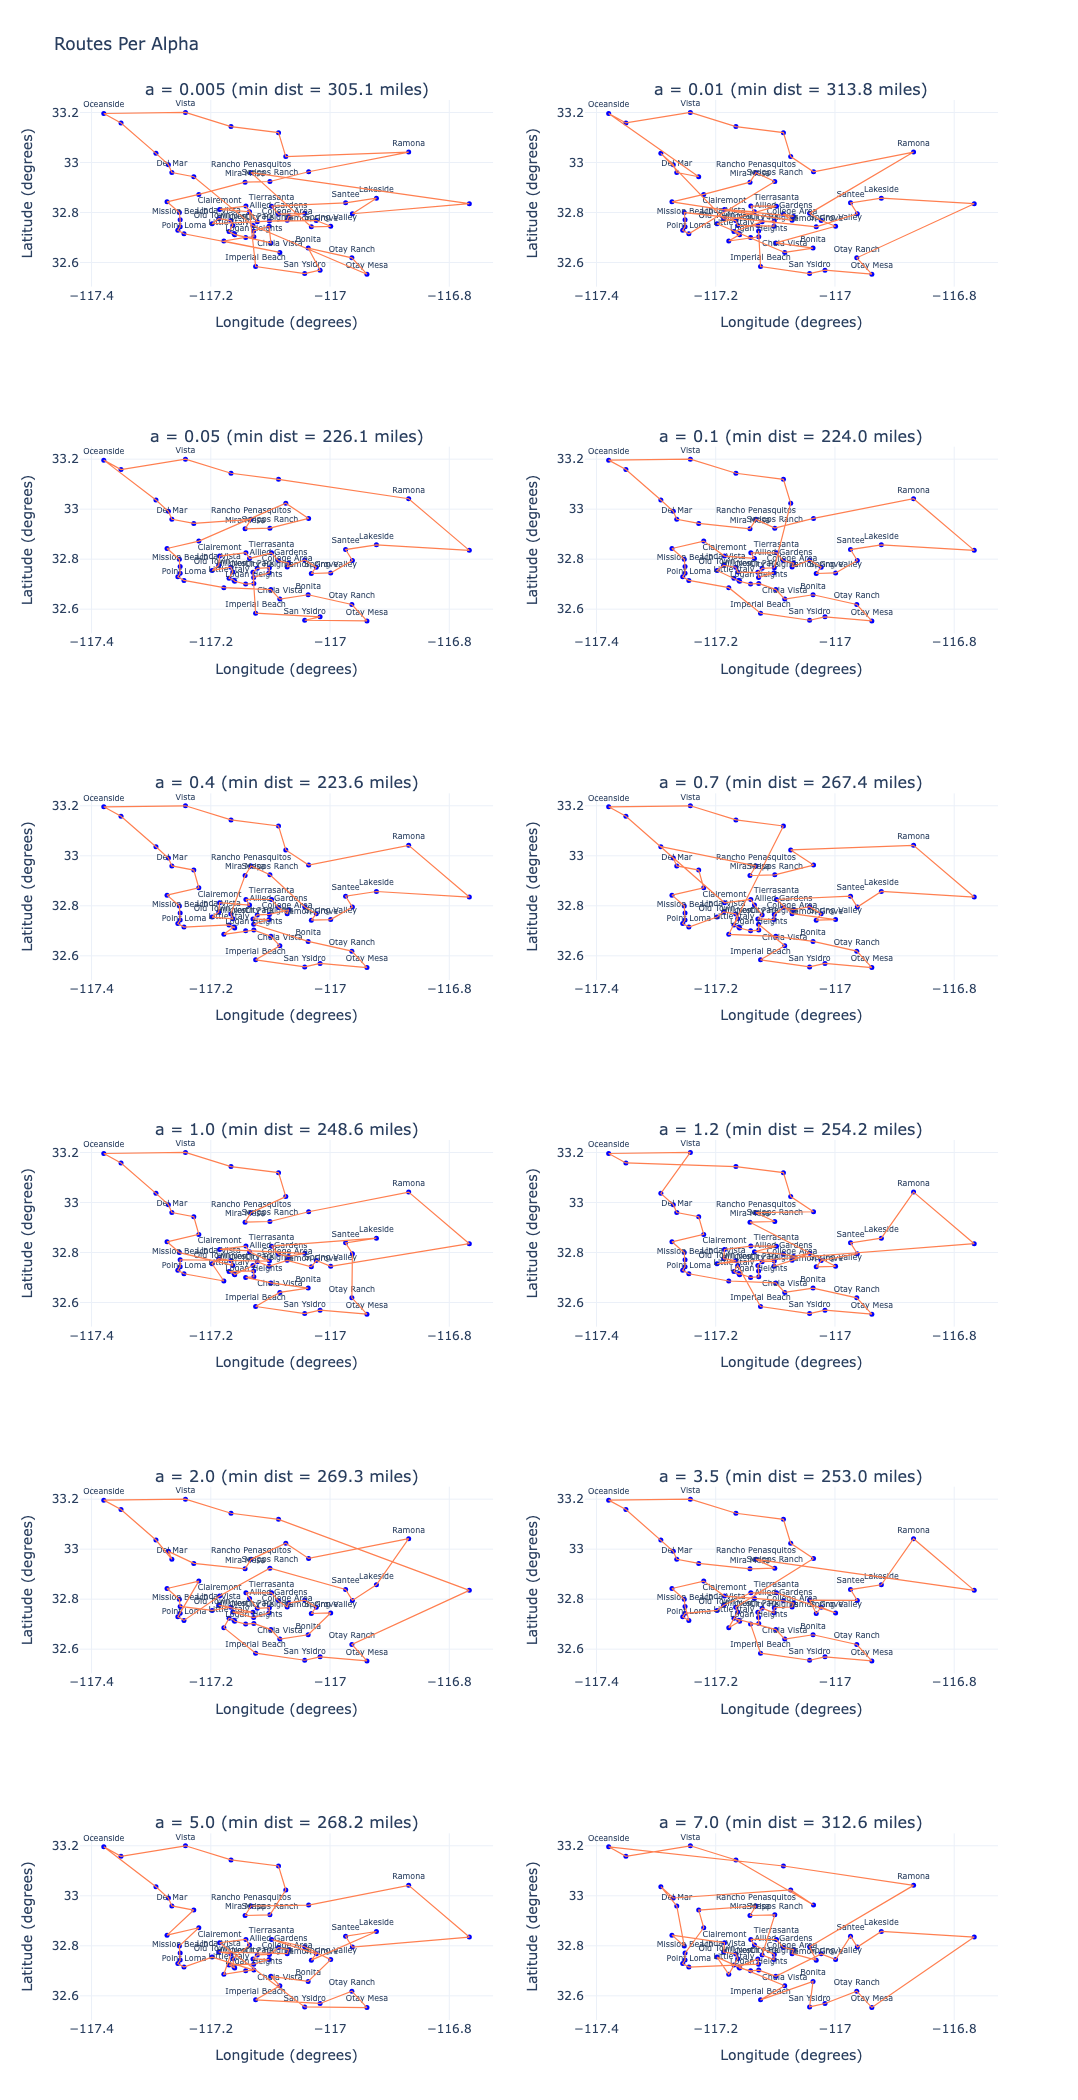

In [4]:
# ANA670 - Week 4 HW - Q4
from plotly.subplots import make_subplots

seed, iters, ants, p_pow, d_pow, reward, n_labels = 42, 60, 30, 2.5, 1.0, 5.0, 30
alpha_options = [0.005, 0.01, 0.05, 0.1, 0.4, 0.7, 1.0, 1.2, 2.0, 3.5, 5.0, 7.0]
np.random.seed(seed)

cities = {
    "Downtown SD": [32.7157, -117.1611], "Old Town": [32.7549, -117.1978], "Hillcrest": [32.7483, -117.1631], "North Park": [32.7475, -117.1293],
    "Ocean Beach": [32.7431, -117.2514], "Pacific Beach": [32.7997, -117.2527], "La Jolla": [32.8427, -117.2734], "Mission Valley": [32.7676, -117.1664],
    "Coronado": [32.6859, -117.1781], "Little Italy": [32.7237, -117.1694], "Ocean Crest": [32.5694, -117.0167], "Point Loma": [32.7150, -117.2450],
    "Clairemont": [32.8122, -117.1853], "South Park": [32.7264, -117.1281], "Gaslamp": [32.7114, -117.1599], "University City": [32.8722, -117.2201],
    "Mira Mesa": [32.9212, -117.1425], "Rancho Bernardo": [33.0234, -117.0742], "Scripps Ranch": [32.9239, -117.1009], "Tierrasanta": [32.8252, -117.0981],
    "Linda Vista": [32.7753, -117.1867], "Serra Mesa": [32.8028, -117.1350], "Kearny Mesa": [32.8256, -117.1411], "City Heights": [32.7451, -117.1023],
    "College Area": [32.7686, -117.0719], "Normal Heights": [32.7634, -117.1221], "Kensington": [32.7656, -117.1017], "Barrio Logan": [32.7001, -117.1415],
    "Logan Heights": [32.7028, -117.1278], "San Ysidro": [32.5556, -117.0425], "Carmel Valley": [32.9430, -117.2285], "Del Mar": [32.9595, -117.2653],
    "Solana Beach": [32.9912, -117.2711], "Encinitas": [33.0364, -117.2920], "Carlsbad": [33.1581, -117.3506], "Oceanside": [33.1959, -117.3795],
    "Vista": [33.2000, -117.2425], "San Marcos": [33.1434, -117.1661], "Escondido": [33.1192, -117.0864], "Poway": [32.9628, -117.0359],
    "Ramona": [33.0417, -116.8681], "Alpine": [32.8351, -116.7664], "El Cajon": [32.7948, -116.9625], "Lakeside": [32.8573, -116.9222],
    "Santee": [32.8384, -116.9739], "La Mesa": [32.7678, -117.0231], "Lemon Grove": [32.7426, -117.0314], "Spring Valley": [32.7448, -116.9989],
    "National City": [32.6781, -117.0992], "Chula Vista": [32.6401, -117.0842], "Imperial Beach": [32.5839, -117.1248], "Bonita": [32.6576, -117.0367],
    "Otay Mesa": [32.5531, -116.9381], "Mission Beach": [32.7709, -117.2514], "Sunset Cliffs": [32.7292, -117.2553], "Allied Gardens": [32.7931, -117.0864],
    "San Carlos": [32.7964, -117.0425], "Del Cerro": [32.7842, -117.0694], "Otay Ranch": [32.6186, -116.9634], "Rancho Penasquitos": [32.9592, -117.1325]
}
stops, coords = list(cities.keys()), np.array(list(cities.values()))
num_cities = len(stops)

lat, lon = np.radians(coords[:, 0]), np.radians(coords[:, 1])
distances = 2 * 3956 * np.arcsin(np.sqrt(np.sin((lat[:, None] - lat) / 2)**2 + np.cos(lat)[:, None] * np.cos(lat) * np.sin((lon[:, None] - lon) / 2)**2))

print("=== START ===\nLoaded nodes and distance matrix.")
def run_simulation(alpha):
    pheromones = np.ones((num_cities, num_cities))
    best_distance, best_path, history, decay_factor = float('inf'), [], [], np.exp(-alpha)
    print(f"\nRunning alpha = {alpha} (multiplier = {decay_factor:.4f})")
    for cycle in range(iters):
        all_paths, all_scores = [], []
        for _ in range(ants):
            visited = [np.random.randint(num_cities)]
            while len(visited) < num_cities:
                curr = visited[-1]
                options = pheromones[curr].copy()
                options[visited] = 0
                weights = (options ** p_pow) / (distances[curr] ** d_pow + 1e-2)
                if weights.sum() == 0:
                    weights = np.ones(num_cities)
                    weights[visited] = 0
                visited.append(np.random.choice(num_cities, p=weights / weights.sum()))
            visited.append(visited[0])
            score = sum(distances[visited[i], visited[i+1]] for i in range(num_cities))
            all_paths.append(visited)
            all_scores.append(score)
            if score < best_distance:
                best_distance, best_path = score, visited
        
        old_mean = pheromones.mean()
        pheromones *= decay_factor
        for path, score in zip(all_paths, all_scores):
            for i in range(num_cities):
                pheromones[path[i], path[i+1]] += reward / score
        
        if cycle in [0, iters // 2, iters - 1]:
            print(f"  Cycle {cycle:2}: Best distance = {best_distance:.2f} miles")
            print(f"    └─ Scent Check: Evaporated Avg = -{old_mean - pheromones.mean():.4f} | Total Deposited = +{sum(reward/s for s in all_scores)*num_cities:.4f} | Matrix New Avg = {pheromones.mean():.4f}")
        history.append(best_distance)
    return {"path": best_path, "distance": best_distance, "history": history}

results = {alpha: run_simulation(alpha) for alpha in alpha_options}

print("\n=== RESULTS ===")
for alpha, data in results.items():
    print(f"Alpha: {alpha:5} | Distance: {data['distance']:.2f} miles")

print("\n=== METADATA & MATH SUMMARY ===")
print(f"• Sample Size: {num_cities} cities\n• Input Matrix: {distances.shape} distance array\n• Tested Strategies: {len(alpha_options)} alpha settings")
print(f"• Formula 1 (Haversine): d = 2R arcsin(√[sin²(Δlat/2) + cos(lat1)cos(lat2)sin²(Δlon/2)])\n  └─ Data bounds: Max = {np.max(distances):.2f} mi | Min = {np.min(distances[distances > 0]):.2f} mi")
print(f"• Formula 2 (Probability): weight = (pheromone ** {p_pow}) / (distance ** {d_pow} + 0.01)\n  └─ Data bounds: Max Options = {num_cities}")
print(f"• Formula 3 (Decay): pheromone = pheromone * exp(-alpha)\n  └─ Data bounds: Range = {np.exp(-min(alpha_options)):.4f} to {np.exp(-max(alpha_options)):.4f}")
print(f"• Formula 4 (Scent Update): pheromone = pheromone + ({reward} / trip_distance)\n  └─ Data bounds: Best Deposit = +{reward / min(results[a]['distance'] for a in results):.5f} | Worst = +{reward / max(results[a]['distance'] for a in results):.5f}")

best_a = min(results, key=lambda k: results[k]["distance"])
print(f"• Winner: alpha = {best_a} at {results[best_a]['distance']:.2f} miles")

fig_history = go.Figure()
for alpha, data in results.items():
    fig_history.add_trace(go.Scatter(y=data["history"], mode='lines+markers', name=f"a = {alpha} (min dist = {data['distance']:.1f} miles)"))
fig_history.update_layout(title="Distance vs Iterations", xaxis_title="Iterations (cycles)", yaxis_title="Distance (miles)", template="plotly_white")
fig_history.show()

fig_sensitivity = go.Figure(data=[go.Scatter(x=alpha_options, y=[results[alpha]["distance"] for alpha in alpha_options], mode='lines+markers', line=dict(color='teal', width=3))])
fig_sensitivity.update_layout(title="Distance vs Alpha", xaxis_title="Alpha (decay constant)", yaxis_title="Distance (miles)", template="plotly_white")
fig_sensitivity.show()

lbl_idx = np.random.choice(num_cities, size=min(n_labels, num_cities), replace=False)
map_labels = [stops[i] if i in lbl_idx else "" for i in range(num_cities)]
cols = 2
rows = int(np.ceil(len(alpha_options) / cols))
fig_maps = make_subplots(rows=rows, cols=cols, subplot_titles=[f"a = {alpha} (min dist = {results[alpha]['distance']:.1f} miles)" for alpha in alpha_options])

for idx, alpha in enumerate(alpha_options):
    r, c = (idx // cols) + 1, (idx % cols) + 1
    ordered_coords = coords[results[alpha]["path"]]
    fig_maps.add_trace(go.Scatter(x=coords[:, 1], y=coords[:, 0], mode='markers+text', text=map_labels, textposition="top center", textfont=dict(size=8), marker=dict(size=5, color='blue'), showlegend=False), row=r, col=c)
    fig_maps.add_trace(go.Scatter(x=ordered_coords[:, 1], y=ordered_coords[:, 0], mode='lines', line=dict(width=1.2, color='coral'), showlegend=False), row=r, col=c)

fig_maps.update_layout(title_text="Routes Per Alpha", height=350 * rows, template="plotly_white")
for i in range(1, len(alpha_options) + 1):
    fig_maps.update_xaxes(title_text="Longitude (degrees)", row=(i-1)//cols+1, col=(i-1)%cols+1)
    fig_maps.update_yaxes(title_text="Latitude (degrees)", row=(i-1)//cols+1, col=(i-1)%cols+1)
fig_maps.show()

ANA670 - Week 4 HW - Q4 \
$\beta$ shifts the gradient and relocates the global minimum of the landscape, creating a minimum for the swarm to find.

📊 SYSTEM ENGINE TRIAL RUN: n=1 | beta_1=0.5 vs beta_2=5.0
--- Global Configuration Parameters ---
Dimensions: 1
Swarm Size: 30 particles
Total Generations: 50
Search Bounds: -1 <= x_i <= 1
Velocity Vector: v = 0.5*v + 1.5*r1*(p_best-x) + 1.5*r2*(g_best-x)

--> Executing Swarm Path Exploration for Beta = 0.5...
  [Log] Generation 1/50 | Min Cost: -3.0000 | Optimal Dials: [-1.]
  [Log] Generation 17/50 | Min Cost: -3.0000 | Optimal Dials: [-1.]
  [Log] Generation 33/50 | Min Cost: -3.0000 | Optimal Dials: [-1.]
  [Log] Generation 49/50 | Min Cost: -3.0000 | Optimal Dials: [-1.]
  [Log] Generation 50/50 | Min Cost: -3.0000 | Optimal Dials: [-1.]
  [Result] Complete | Global Local Minimum: -3.000000 at Matrix Settings: [-1.]

--> Executing Swarm Path Exploration for Beta = 5.0...
  [Log] Generation 1/50 | Min Cost: -12.0000 | Optimal Dials: [-1.]
  [Log] Generation 17/50 | Min Cost: -12.0000 | Optimal Dials: [-1.]
  [Log] Generation 33/50 | Min Cost: -12.0000 | Optimal Dials: [-1.]
  [Log]

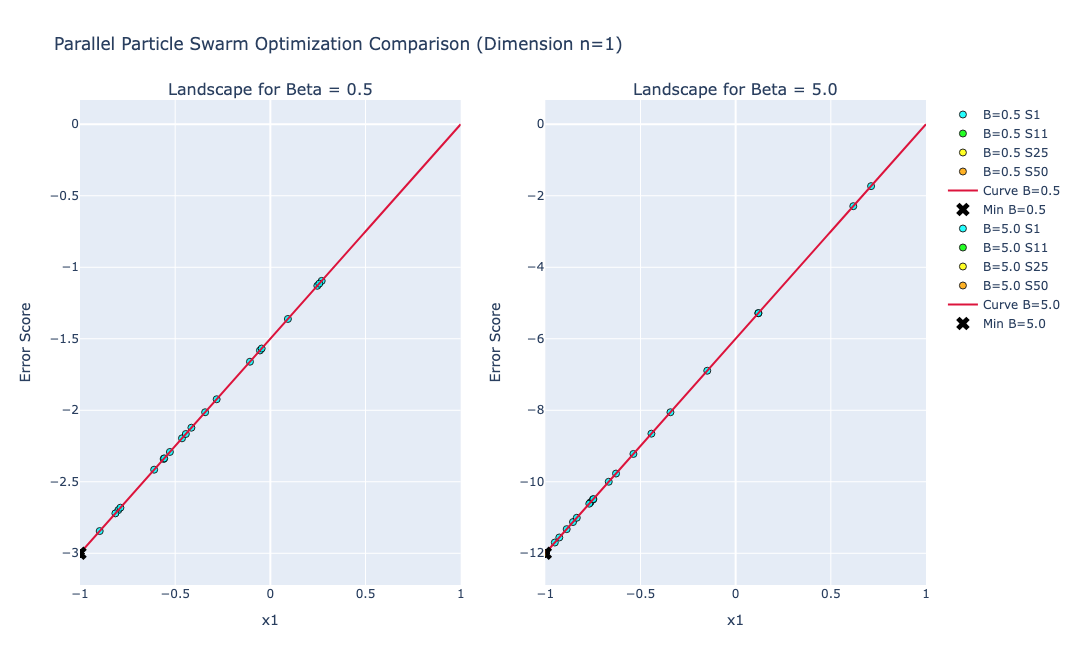

📊 SYSTEM ENGINE TRIAL RUN: n=2 | beta_1=1.5 vs beta_2=7.0
--- Global Configuration Parameters ---
Dimensions: 2
Swarm Size: 30 particles
Total Generations: 50
Search Bounds: -2 <= x_i <= 2
Velocity Vector: v = 0.5*v + 1.5*r1*(p_best-x) + 1.5*r2*(g_best-x)

--> Executing Swarm Path Exploration for Beta = 1.5...
  [Log] Generation 1/50 | Min Cost: -15.1723 | Optimal Dials: [-0.454 -0.58 ]
  [Log] Generation 17/50 | Min Cost: -15.1818 | Optimal Dials: [-0.5   -0.636]
  [Log] Generation 33/50 | Min Cost: -15.1818 | Optimal Dials: [-0.5   -0.636]
  [Log] Generation 49/50 | Min Cost: -15.1818 | Optimal Dials: [-0.5   -0.636]
  [Log] Generation 50/50 | Min Cost: -15.1818 | Optimal Dials: [-0.5   -0.636]
  [Result] Complete | Global Local Minimum: -15.181818 at Matrix Settings: [-0.5    -0.6364]

--> Executing Swarm Path Exploration for Beta = 7.0...
  [Log] Generation 1/50 | Min Cost: -39.7934 | Optimal Dials: [-0.424 -0.797]
  [Log] Generation 17/50 | Min Cost: -39.8409 | Optimal Dials: [-0.

📊 SYSTEM ENGINE TRIAL RUN: n=5 | beta_1=2.0 vs beta_2=9.0
--- Global Configuration Parameters ---
Dimensions: 5
Swarm Size: 30 particles
Total Generations: 50
Search Bounds: -5 <= x_i <= 5
Velocity Vector: v = 0.5*v + 1.5*r1*(p_best-x) + 1.5*r2*(g_best-x)

[Engine Alert] Dimension scale n=5 exceeds 3D visualization physical boundaries.
[Engine Alert] Skipping Plotly visual mapping engine. Running tracking math calculations only...

--> Executing Swarm Path Exploration for Beta = 2.0...
  [Log] Generation 1/50 | Min Cost: -16919.7785 | Optimal Dials: [-5.    -1.026 -3.826 -2.624 -5.   ]
  [Log] Generation 17/50 | Min Cost: -24148.7646 | Optimal Dials: [-5. -5. -5. -5. -5.]
  [Log] Generation 33/50 | Min Cost: -24148.7646 | Optimal Dials: [-5. -5. -5. -5. -5.]
  [Log] Generation 49/50 | Min Cost: -24148.7646 | Optimal Dials: [-5. -5. -5. -5. -5.]
  [Log] Generation 50/50 | Min Cost: -24148.7646 | Optimal Dials: [-5. -5. -5. -5. -5.]
  [Result] Complete | Global Local Minimum: -24148.7645

In [5]:
def run_multi_beta_experiment(n, b1, b2, steps=50, size=30, sel_steps=None):
    if sel_steps is None:
        sel_steps = [0, 10, 24, 49]
    low, high = -n, n
    
    def objective(x, b_val):
        v = 0.0
        for j in range(1, len(x) + 1):
            for i in range(1, len(x) + 1):
                v += (i**j + b_val) * ((x[i-1] / i)**j - 1)
        return v

    w, c1, c2 = 0.5, 1.5, 1.5
    colors = ['cyan', 'lime', 'yellow', 'orange', 'magenta']
    
    print(f"==================================================")
    print(f"📊 SYSTEM ENGINE TRIAL RUN: n={n} | beta_1={b1} vs beta_2={b2}")
    print(f"==================================================")
    print(f"--- Global Configuration Parameters ---\nDimensions: {n}\nSwarm Size: {size} particles\nTotal Generations: {steps}\nSearch Bounds: {low} <= x_i <= {high}")
    print(f"Velocity Vector: v = {w}*v + {c1}*r1*(p_best-x) + {c2}*r2*(g_best-x)\n")

    can_plot = n <= 2
    if not can_plot:
        print(f"[Engine Alert] Dimension scale n={n} exceeds 3D visualization physical boundaries.")
        print(f"[Engine Alert] Skipping Plotly visual mapping engine. Running tracking math calculations only...\n")

    if can_plot:
        if n == 1:
            fig = make_subplots(rows=1, cols=2, subplot_titles=(f"Landscape for Beta = {b1}", f"Landscape for Beta = {b2}"))
        else:
            fig = make_subplots(rows=1, cols=2, specs=[[{'type': 'surface'}, {'type': 'surface'}]], subplot_titles=(f"Landscape for Beta = {b1}", f"Landscape for Beta = {b2}"))

    for col_idx, current_b in enumerate([b1, b2], start=1):
        print(f"--> Executing Swarm Path Exploration for Beta = {current_b}...")
        pos = np.random.uniform(low, high, (size, n))
        vel = np.random.uniform(-1, 1, (size, n))
        p_best = np.copy(pos)
        p_sc = np.array([objective(p, current_b) for p in pos])
        g_best = np.copy(p_best[np.argmin(p_sc)])
        g_sc = p_sc[np.argmin(p_sc)]
        
        for t in range(steps):
            for i in range(size):
                r1, r2 = np.random.rand(n), np.random.rand(n)
                vel[i] = w * vel[i] + c1 * r1 * (p_best[i] - pos[i]) + c2 * r2 * (g_best - pos[i])
                pos[i] = np.clip(pos[i] + vel[i], low, high)
                sc = objective(pos[i], current_b)
                if sc < p_sc[i]:
                    p_sc[i], p_best[i] = sc, np.copy(pos[i])
                    if sc < g_sc: g_sc, g_best = sc, np.copy(pos[i])
            
            if can_plot and (t in sel_steps):
                z_vals = np.array([objective(p, current_b) for p in pos])
                color_str = colors[sel_steps.index(t) % len(colors)]
                if n == 1:
                    fig.add_trace(go.Scatter(
                        x=pos[:, 0], y=z_vals, mode='markers', name=f'B={current_b} S{t+1}',
                        marker=dict(size=7, color=color_str, opacity=0.85, line=dict(width=1, color='black'))
                    ), row=1, col=col_idx)
                else:
                    fig.add_trace(go.Scatter3d(
                        x=pos[:, 0], y=pos[:, 1], z=z_vals, mode='markers', name=f'B={current_b} S{t+1}',
                        marker=dict(size=5, color=color_str, opacity=0.85, line=dict(width=1, color='black'))
                    ), row=1, col=col_idx)
                    
            if t % max(1, steps // 3) == 0 or t == steps - 1:
                print(f"  [Log] Generation {t+1}/{steps} | Min Cost: {g_sc:.4f} | Optimal Dials: {np.round(g_best, 3)}")
                
        print(f"  [Result] Complete | Global Local Minimum: {g_sc:.6f} at Matrix Settings: {np.round(g_best, 4)}\n")

        if can_plot:
            if n == 1:
                x_line = np.linspace(low, high, 200)
                y_line = np.array([objective([xv], current_b) for xv in x_line])
                fig.add_trace(go.Scatter(x=x_line, y=y_line, mode='lines', name=f'Curve B={current_b}', line=dict(color='crimson', width=2)), row=1, col=col_idx)
                fig.add_trace(go.Scatter(x=[g_best[0]], y=[g_sc], mode='markers', name=f'Min B={current_b}', marker=dict(size=12, color='black', symbol='x')), row=1, col=col_idx)
                fig.update_xaxes(title_text='x1', range=[low, high], row=1, col=col_idx)
                fig.update_yaxes(title_text='Error Score', row=1, col=col_idx)
            else:
                x1, x2 = np.linspace(low, high, 40), np.linspace(low, high, 40)
                X1, X2 = np.meshgrid(x1, x2)
                Z = np.array([[objective([xv, yv], current_b) for xv in x1] for yv in x2])
                fig.add_trace(go.Surface(x=x1, y=x2, z=Z, colorscale='Plasma', opacity=0.45, showscale=False), row=1, col=col_idx)
                fig.add_trace(go.Scatter3d(x=[g_best[0]], y=[g_best[1]], z=[g_sc], mode='markers', name=f'Min B={current_b}', marker=dict(size=9, color='red', symbol='diamond')), row=1, col=col_idx)

    if can_plot:
        fig.update_layout(
            title=f"Parallel Particle Swarm Optimization Comparison (Dimension n={n})",
            width=1100, height=650, showlegend=True
        )
        if n > 1:
            fig.update_layout(
                scene=dict(xaxis_title='x1', yaxis_title='x2', zaxis_title='Error', xaxis=dict(range=[low, high]), yaxis=dict(range=[low, high])),
                scene2=dict(xaxis_title='x1', yaxis_title='x2', zaxis_title='Error', xaxis=dict(range=[low, high]), yaxis=dict(range=[low, high]))
            )
        fig.show()

run_multi_beta_experiment(n=1, b1=0.5, b2=5.0)
run_multi_beta_experiment(n=2, b1=1.5, b2=7.0)
run_multi_beta_experiment(n=5, b1=2.0, b2=9.0)
run_multi_beta_experiment(n=6, b1=2.5, b2=11.0)